# 03 - Exploracion de Imagenes

## Objetivo

Conocer el estado de las imágenes de entrenamiento antes de preprocesarlas, y cuantificar los problemas que pueden afectar a la segmentación y a la clasificación: tamaño de las imágenes, esquinas negras del dermatoscopio y presencia de pelos.

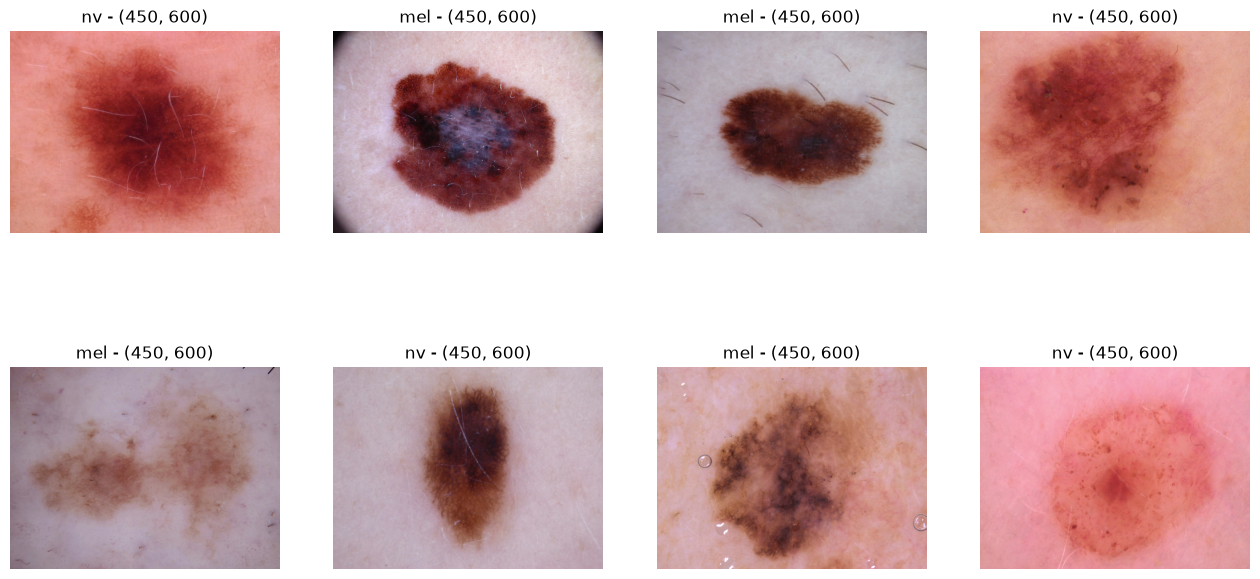

In [3]:
from pathlib import Path
import pandas as pd
import cv2
import matplotlib.pyplot as plt

PROCESSED = Path("../data/processed")
IMGS = PROCESSED / "images"

train_df = pd.read_csv(PROCESSED / "train.csv")

def cargar(image_id):
    img = cv2.imread(str(IMGS / f"{image_id}.jpg"))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

muestras = train_df.sample(8, random_state=1)

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, fila) in zip(axs.ravel(), muestras.iterrows()):
    img = cargar(fila["image_id"])
    ax.imshow(img)
    ax.set_title(f"{fila['dx']} - {img.shape[:2]}")
    ax.axis("off")
plt.show()

Vemos que en algunas imagenes existe la presencia de pelos y esquinas negras.